# Projet 2

In [13]:
import os, re
from glob import glob as ls
from PIL import Image, ImageDraw
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import pandas as pd
import seaborn as sns; sns.set()
import qgrid
from PIL import Image
%load_ext autoreload
%autoreload 2
import warnings
warnings.filterwarnings("ignore")
from sys import path
from intro_science_donnees import *
from intro_science_donnees import data
from utilities import *


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [14]:
dataset_dir = 'data/512x512/'
images = load_images(dataset_dir, "*.jpg")

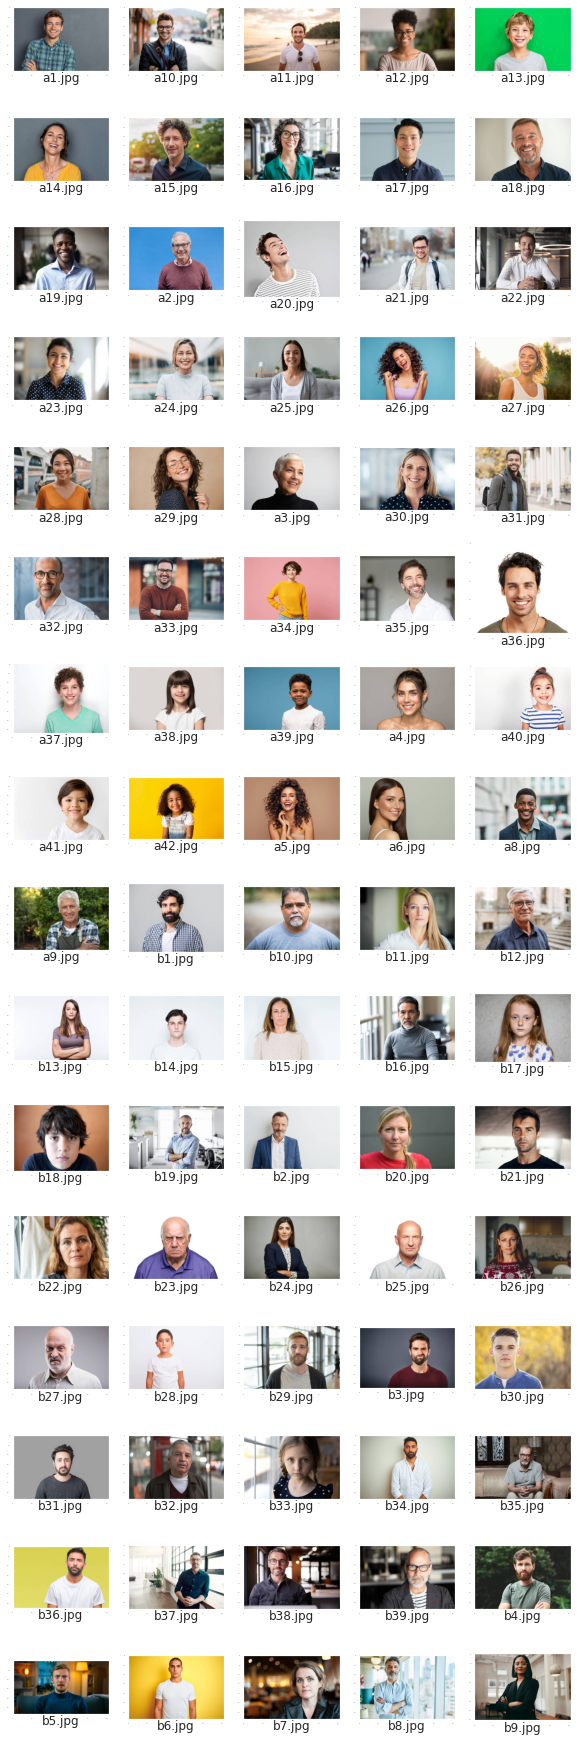

In [15]:
image_grid(images, titles=images.index)

In [16]:
images

a1.jpg     <PIL.JpegImagePlugin.JpegImageFile image mode=...
a10.jpg    <PIL.JpegImagePlugin.JpegImageFile image mode=...
a11.jpg    <PIL.JpegImagePlugin.JpegImageFile image mode=...
a12.jpg    <PIL.JpegImagePlugin.JpegImageFile image mode=...
a13.jpg    <PIL.JpegImagePlugin.JpegImageFile image mode=...
                                 ...                        
b5.jpg     <PIL.JpegImagePlugin.JpegImageFile image mode=...
b6.jpg     <PIL.JpegImagePlugin.JpegImageFile image mode=...
b7.jpg     <PIL.JpegImagePlugin.JpegImageFile image mode=...
b8.jpg     <PIL.JpegImagePlugin.JpegImageFile image mode=...
b9.jpg     <PIL.JpegImagePlugin.JpegImageFile image mode=...
Length: 80, dtype: object

In [17]:
type(images)

pandas.core.series.Series

In [18]:
images.index

Index(['a1.jpg', 'a10.jpg', 'a11.jpg', 'a12.jpg', 'a13.jpg', 'a14.jpg',
       'a15.jpg', 'a16.jpg', 'a17.jpg', 'a18.jpg', 'a19.jpg', 'a2.jpg',
       'a20.jpg', 'a21.jpg', 'a22.jpg', 'a23.jpg', 'a24.jpg', 'a25.jpg',
       'a26.jpg', 'a27.jpg', 'a28.jpg', 'a29.jpg', 'a3.jpg', 'a30.jpg',
       'a31.jpg', 'a32.jpg', 'a33.jpg', 'a34.jpg', 'a35.jpg', 'a36.jpg',
       'a37.jpg', 'a38.jpg', 'a39.jpg', 'a4.jpg', 'a40.jpg', 'a41.jpg',
       'a42.jpg', 'a5.jpg', 'a6.jpg', 'a8.jpg', 'a9.jpg', 'b1.jpg', 'b10.jpg',
       'b11.jpg', 'b12.jpg', 'b13.jpg', 'b14.jpg', 'b15.jpg', 'b16.jpg',
       'b17.jpg', 'b18.jpg', 'b19.jpg', 'b2.jpg', 'b20.jpg', 'b21.jpg',
       'b22.jpg', 'b23.jpg', 'b24.jpg', 'b25.jpg', 'b26.jpg', 'b27.jpg',
       'b28.jpg', 'b29.jpg', 'b3.jpg', 'b30.jpg', 'b31.jpg', 'b32.jpg',
       'b33.jpg', 'b34.jpg', 'b35.jpg', 'b36.jpg', 'b37.jpg', 'b38.jpg',
       'b39.jpg', 'b4.jpg', 'b5.jpg', 'b6.jpg', 'b7.jpg', 'b8.jpg', 'b9.jpg'],
      dtype='object')

In [19]:
d = {"Class": [1 if s[0] == 'a' else -1 for s in images.index]
}

In [20]:
data = pd.DataFrame(data=d, index=images.index)
data

,Class
a1.jpg,1
a10.jpg,1
a11.jpg,1
a12.jpg,1
a13.jpg,1
...,...
b5.jpg,-1
b6.jpg,-1
b7.jpg,-1
b8.jpg,-1


In [21]:
def calc_seuil(img : Image.Image) -> int:
    n = np.array(img)
    G = np.min(n[:, :, 0:3], axis=2)
    return((np.mean(G) + np.std(G))/2)

def invert(n : np.ndarray, force : bool = False) -> np.ndarray:
    G = n.mean()
    return np.invert(n) if force or G > 0.5 else n


img = images[6]
image_grid([invert(foreground_filter(img, calc_seuil(img))), invert(foreground_filter(img, calc_seuil(img)))])
print(np.argwhere(invert(foreground_filter(img, calc_seuil(img)))))

[[  0   0]
 [  0   1]
 [  0   2]
 ...
 [339 121]
 [339 122]
 [339 123]]


In [22]:
img_foreground = np.array([invert(foreground_filter(img, calc_seuil(img))) for img in images])

In [23]:
img_foreground

array([array([[False, False, False, ..., False, False, False],
              [False, False, False, ..., False, False, False],
              [False, False, False, ..., False, False, False],
              ...,
              [ True,  True,  True, ..., False, False, False],
              [ True,  True,  True, ..., False, False, False],
              [ True,  True,  True, ..., False, False, False]]),
       array([[ True,  True,  True, ...,  True,  True,  True],
              [ True,  True,  True, ...,  True,  True,  True],
              [ True,  True,  True, ...,  True,  True,  True],
              ...,
              [ True,  True,  True, ..., False, False, False],
              [ True,  True,  True, ..., False, False, False],
              [ True,  True,  True, ..., False, False, False]]),
       array([[False, False, False, ..., False, False, False],
              [False, False, False, ..., False, False, False],
              [False, False, False, ..., False, False, False],
             

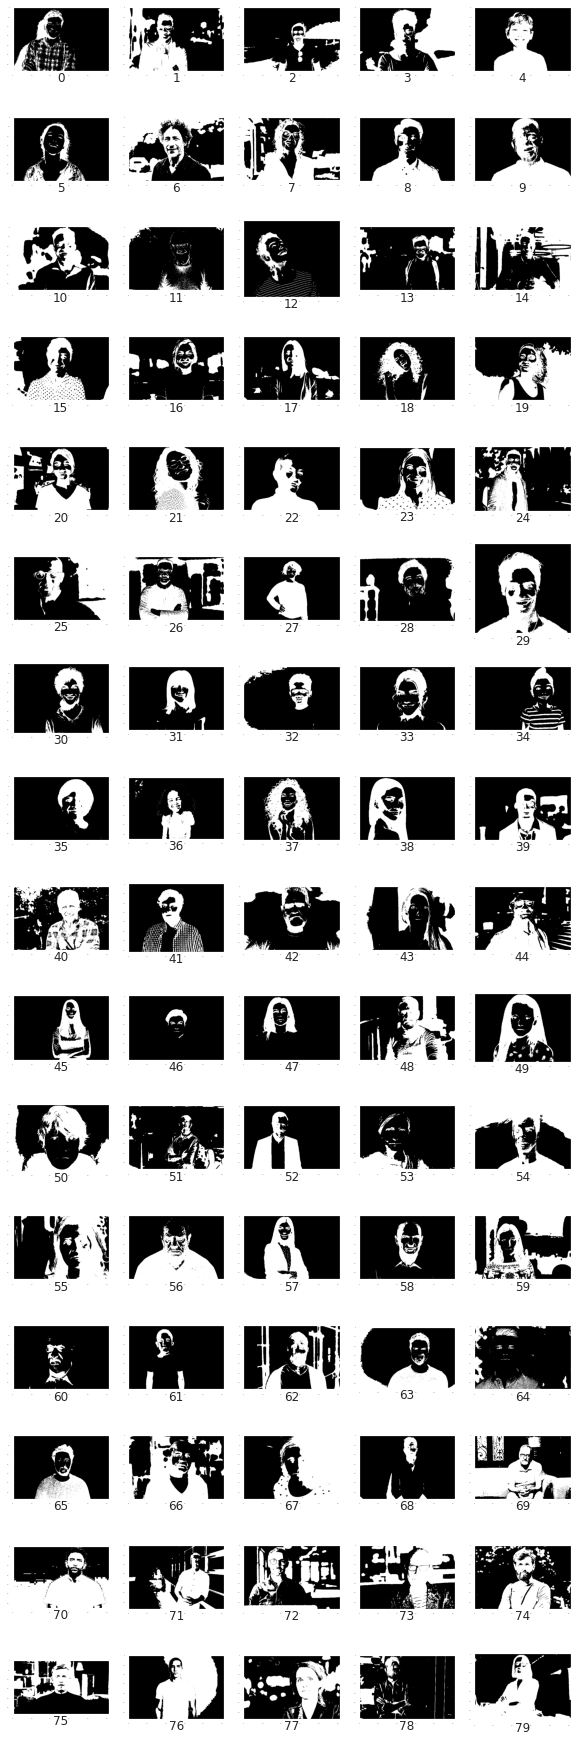

In [24]:
image_grid(img_foreground)

In [25]:
img_barycentre = np.array([place_barycentre(img) for img in img_foreground])

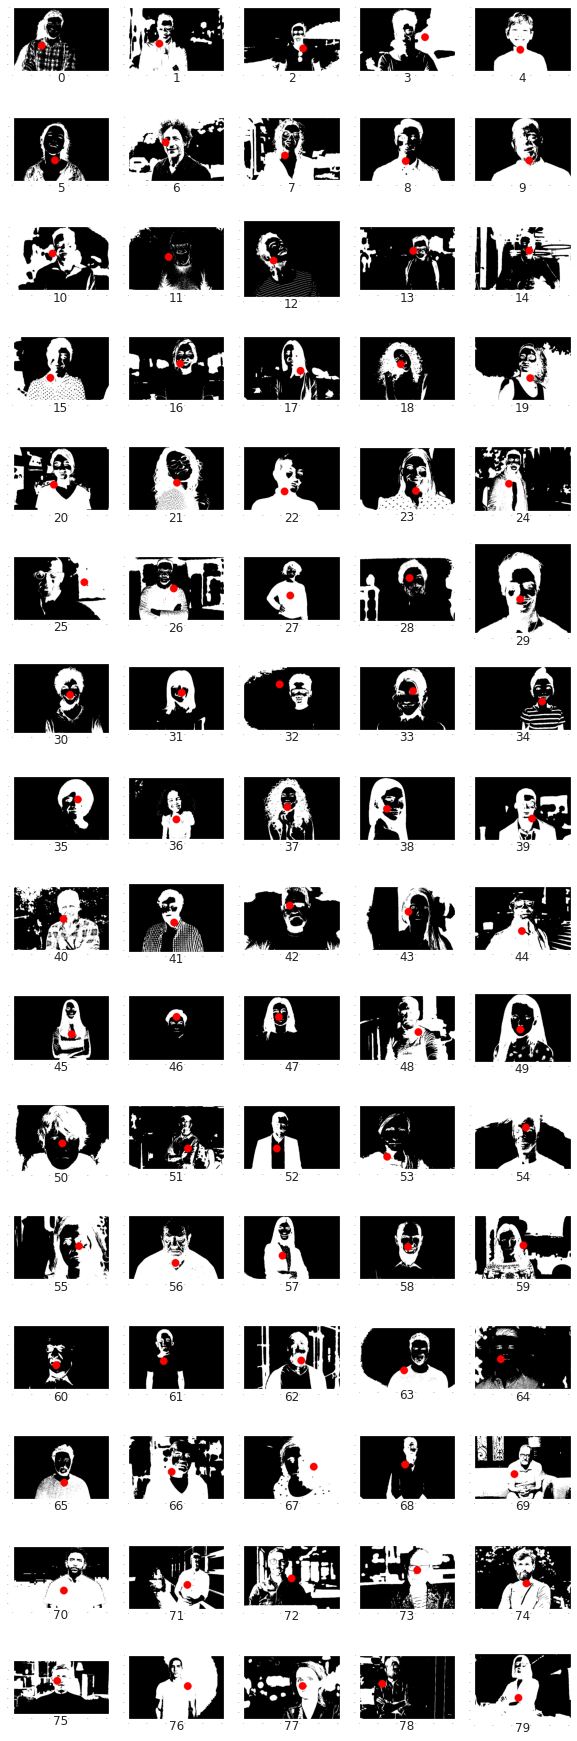

In [26]:
image_grid(img_barycentre)

In [27]:
img_barycentre

array([<PIL.Image.Image image mode=RGB size=512x340 at 0x7F105E9BD8B0>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7F105EC63D30>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7F105EC63700>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7F105EB78B80>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7F10646D2040>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7F105F1102B0>,
       <PIL.Image.Image image mode=RGB size=512x340 at 0x7F105E8FC610>,
       <PIL.Image.Image image mode=RGB size=512x337 at 0x7F1064329D90>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7F1064329D60>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7F1064329DF0>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7F1064329F40>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7F1064329A90>,
       <PIL.Image.Image image mode=RGB size=512x410 at 0x7F105F0E15B0>,
       <PIL.Image.Image image mode=RGB size=512x341 at 0x7F10643

In [28]:
img_foreground[0].shape

(340, 512)

In [29]:
images_cropped = pd.Series([crop_around_barycentre(img_foreground[i], images[i]) for i in range(len(images))])
images_cropped.index = images.index

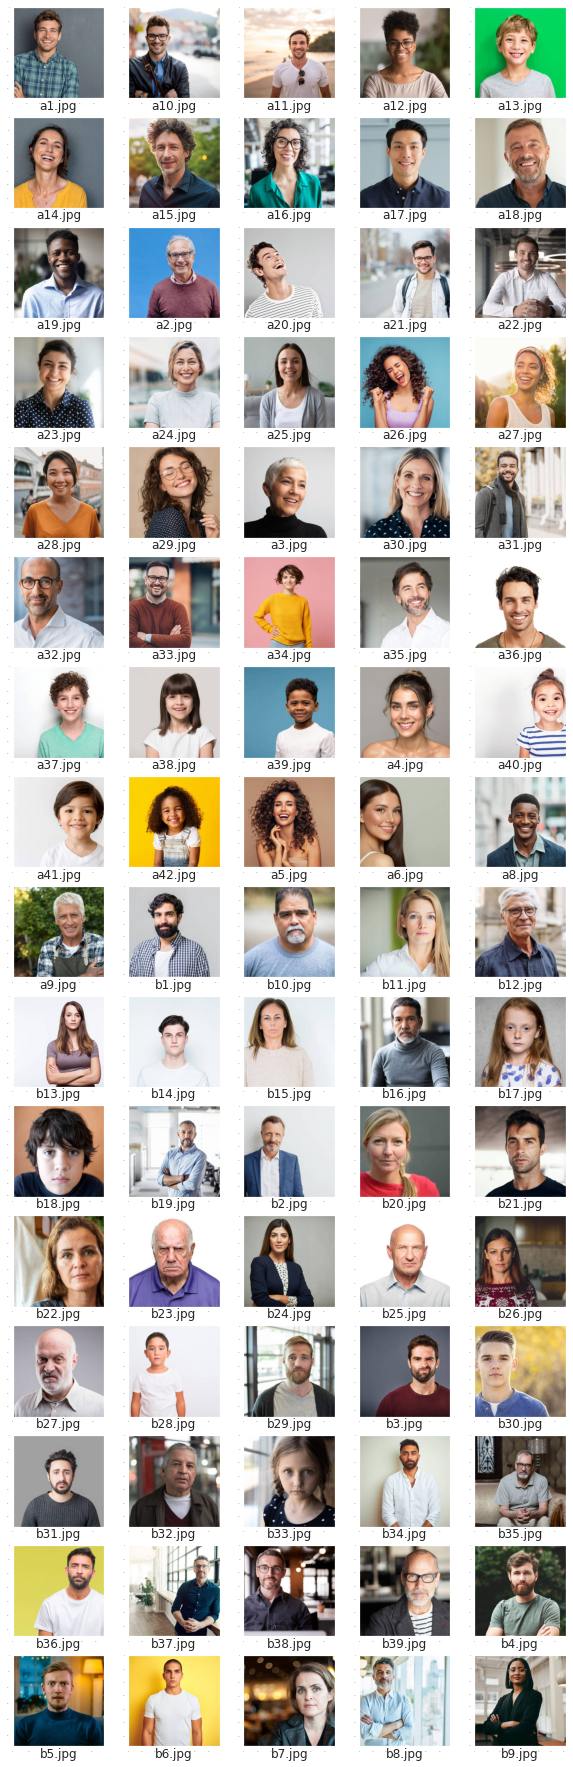

In [30]:
image_grid(images_cropped, titles=images_cropped.index)

In [31]:
images_resize = pd.Series([img.resize((64, 64)) for img in images_cropped])
images_resize.index = images.index

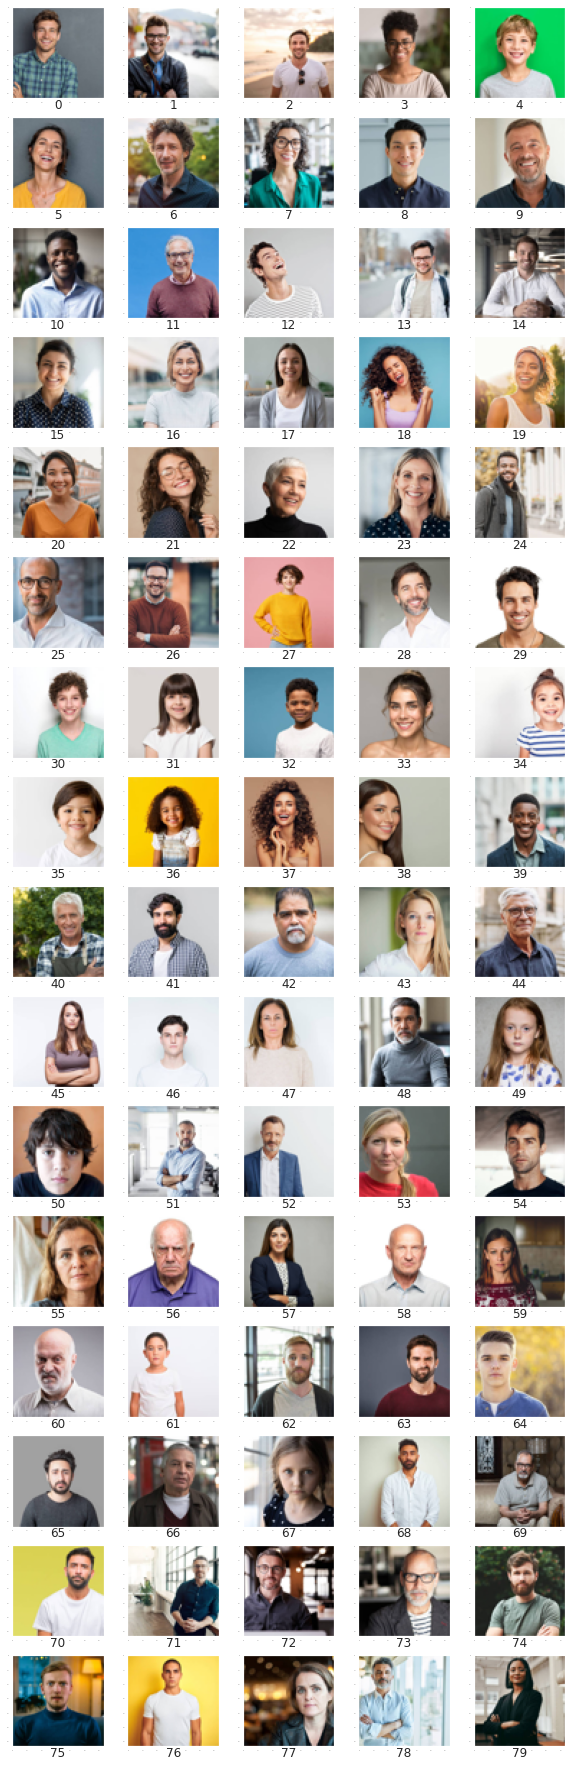

In [32]:
image_grid(images_resize)

In [33]:
print(np.array([images_cropped]))

[[<PIL.Image.Image image mode=RGB size=340x340 at 0x7F1067166580>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7F1064D0C790>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7F1067166D00>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7F10672410A0>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7F1067241B50>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7F1067241310>
  <PIL.Image.Image image mode=RGB size=340x340 at 0x7F105CE918E0>
  <PIL.Image.Image image mode=RGB size=337x337 at 0x7F1064329E80>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7F1064329CD0>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7F1064329C40>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7F10671BC280>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7F10671BC700>
  <PIL.Image.Image image mode=RGB size=410x410 at 0x7F10671BC9A0>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7F10671BC400>
  <PIL.Image.Image image mode=RGB size=341x341 at 0x7F10671BC040>
  <PIL.Ima

In [34]:
print(np.array(images_resize))

[<PIL.Image.Image image mode=RGB size=64x64 at 0x7F105CB87670>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7F105D06BE20>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7F105B076DC0>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7F105B076A30>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7F105B076D30>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7F105B076400>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7F105B0764F0>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7F105B076B50>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7F105B076A00>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7F105B076E50>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7F105B076FA0>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7F105B063C40>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7F105B063C10>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7F105B063880>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7F105B063850>
 <PIL.Image.Image image mode=RGB size=64x64 at 0x7F105B

In [35]:
#for i,img in enumerate(images_resize):
#    img.save("data/resize/"+images_resize.index[i])


In [36]:
foreground = pd.Series([invert(foreground_filter(img, 60)) for img in images_resize])

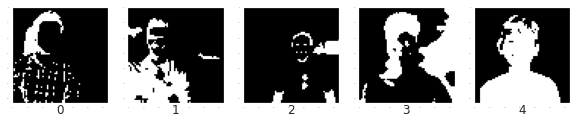

In [37]:
image_grid(foreground.head())

In [38]:
def color_correlation_filter(
    img: Union[Image.Image, np.ndarray], color: np.ndarray
) -> np.ndarray:
    """Return a grey-level image measuring the correlation of the pixels
    with the given color."""
    N = np.array(img, dtype='float64')
    r = np.array([[abs(np.corrcoef(linPix[i][0:3], color)[0, 1]) for i in range(len(linPix))] for linPix in N])
    return r

In [39]:
def color_fist_line(img : Image.Image) -> tuple:
    color = r, g, b = 0, 0, 0
    img_color = np.array(img)[:, 0, :]
    L = len(img_color)
    for l in img_color:
        r,g, b = (r+l[0], g+l[1], b+l[2])
    color = r, g, b = r/L, g/L, b/L
    return r,g, b

def color_fist_colonne(img : Image.Image) -> tuple:
    color = r, g, b = 0, 0, 0
    img_color = np.array(img)[0, :, :]
    L = len(img_color)
    for l in img_color:
        r,g, b = (r+l[0], g+l[1], b+l[2])
    color = r, g, b = r/L, g/L, b/L
    return r,g, b

def color_last_colonne(img : Image.Image) -> tuple:
    color = r, g, b = 0, 0, 0
    img_color = np.array(img)[-1, :, :]
    L = len(img_color)
    for l in img_color:
        r,g, b = (r+l[0], g+l[1], b+l[2])
    color = r, g, b = r/L, g/L, b/L
    return r,g, b

In [40]:
background = np.array([(color_correlation_filter(img, color_fist_line(img)) + color_correlation_filter(img, color_fist_colonne(img)) + color_correlation_filter(img, color_last_colonne(img))) for img in images_resize])

In [41]:
background2 = np.array([(color_correlation_filter(img, (0,0,255)) + color_correlation_filter(img, (0,255,0))) for img in images_resize])

In [42]:
moyennes = [background[i].mean for i in range(len(background))]

In [43]:
contour = np.array([contours(img) for img in images_resize])

In [44]:
def superieur_couleur(M : np.ndarray) -> np.ndarray:
    N = [[False for j in range(len(M))] for i in range(len(M))]


    for x, l in enumerate(M):
        for y, l2 in enumerate(l):
            r, g, b = l2 > 40
            N[x][y] = r and g and b
    return N

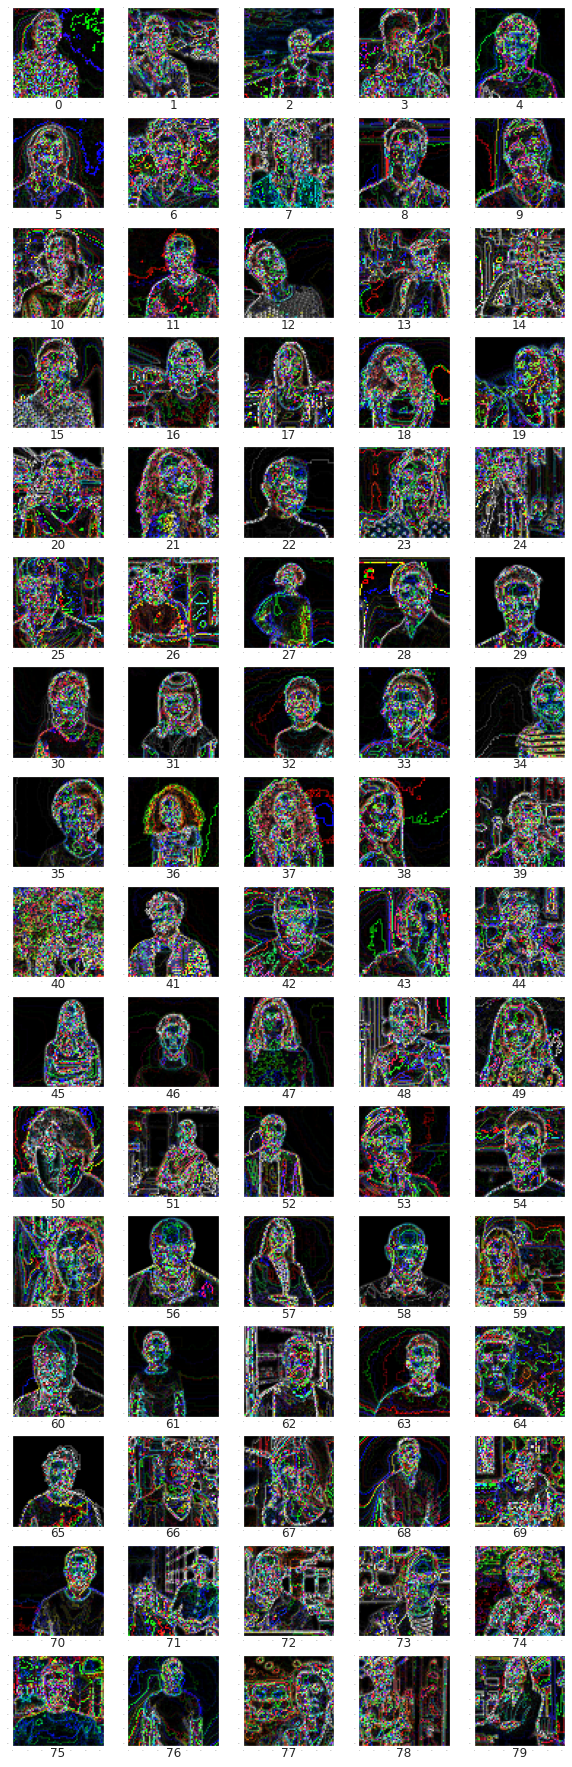

In [45]:
image_grid(contour)

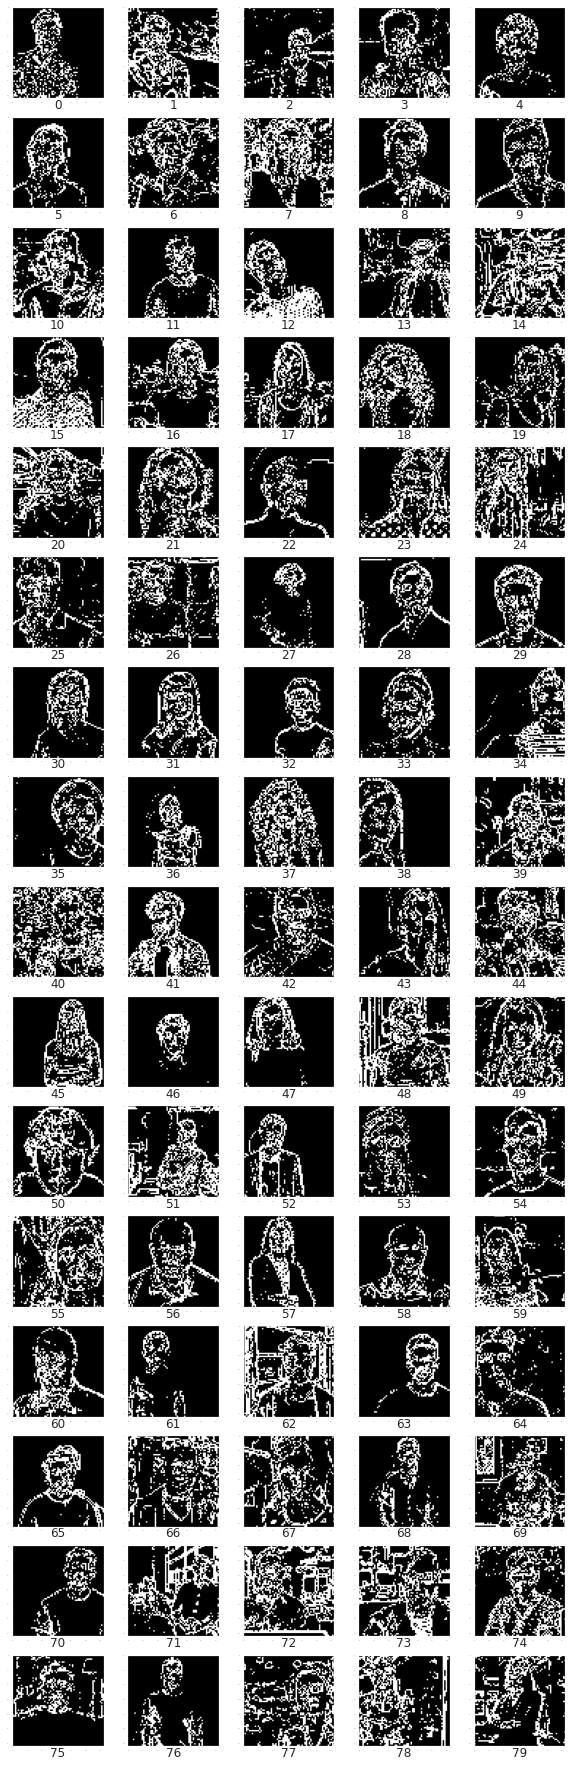

In [46]:
image_grid([superieur_couleur(img) for img in contour])

Nous allons utiliser un réseau pré-entraîné appelé `MobileNet`, dont
l'architecture a été optimisé pour fonctionner sur les téléphones
portables. Il a été pré-entraîné pour reconnaître mille catégories
différentes (dont des animaux, des objets de la vie courante etc.).

Depuis la librairie `keras`, importons le modèle pré-entraîné sur la
base de donnée `imagenet` :

In [1]:
import tensorflow as tf
tf.config.run_functions_eagerly(True)

mobilenet = tf.keras.applications.MobileNet(include_top=False, weights='imagenet', input_shape = (64,64,3))

2022-04-15 07:33:01.414275: I tensorflow/core/platform/cpu_feature_guard.cc:142] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


Observons l'architecture en couches de ce réseau de neurones; chaque
ligne ci-dessous décrit brièvement l'une des couches successives :

In [48]:
mobilenet.summary()

Model: "mobilenet_1.00_224"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         [(None, 64, 64, 3)]       0         
_________________________________________________________________
conv1 (Conv2D)               (None, 32, 32, 32)        864       
_________________________________________________________________
conv1_bn (BatchNormalization (None, 32, 32, 32)        128       
_________________________________________________________________
conv1_relu (ReLU)            (None, 32, 32, 32)        0         
_________________________________________________________________
conv_dw_1 (DepthwiseConv2D)  (None, 32, 32, 32)        288       
_________________________________________________________________
conv_dw_1_bn (BatchNormaliza (None, 32, 32, 32)        128       
_________________________________________________________________
conv_dw_1_relu (ReLU)        (None, 32, 32, 32) 

En déclarant le réseau avec le paramètre `include_top=False`, on a
retiré la dernière couche de neurone. **Le transfert d'apprentissage
va pouvoir être fait en ajoutant des nouvelles couches de neurones
entraînables à la fin de ce réseau pré-entraîné (dont les paramètres
vont être gelés).** Ainsi, on pourra entraîner seulement les dernières
couches de notre réseau sans avoir à réentraîner tout le réseau, ce
qui nécessiterait autrement une puissante carte graphique. En d'autres
termes, le réseau `mobilenet` va nous donner des attributs abstraits
sur lesquels nous allons réentraîner un nouveau réseau de neurones,
plus petit.

On commence par geler les poids du réseau `mobilenet` :

In [49]:
for layer in mobilenet.layers:
    layer.trainable=False

Vérifiez que tous les paramètres de `mobilenet` sont à présent
non-entraînables :

In [50]:
mobilenet.summary()

Model: "mobilenet_1.00_224"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         [(None, 64, 64, 3)]       0         
_________________________________________________________________
conv1 (Conv2D)               (None, 32, 32, 32)        864       
_________________________________________________________________
conv1_bn (BatchNormalization (None, 32, 32, 32)        128       
_________________________________________________________________
conv1_relu (ReLU)            (None, 32, 32, 32)        0         
_________________________________________________________________
conv_dw_1 (DepthwiseConv2D)  (None, 32, 32, 32)        288       
_________________________________________________________________
conv_dw_1_bn (BatchNormaliza (None, 32, 32, 32)        128       
_________________________________________________________________
conv_dw_1_relu (ReLU)        (None, 32, 32, 32) 

On va à présent ajouter de nouvelles couches entraînables de neurones :

In [51]:
from tensorflow import keras
from keras.models import Model
from keras.layers import Dense,GlobalAveragePooling2D

myneuralnet = keras.Sequential(
    [
        mobilenet,
        GlobalAveragePooling2D(),
        Dense(64, activation="relu", name="layer1"),
        Dense(64, activation="relu", name="layer2"),
        Dense(2, activation="softmax",name="layer3"),
    ]
)

Configurons le réseau `mobilenet` pour prendre en entrée des images de
taille `(32,32,3)`:

In [52]:
myneuralnet.build((None,64,64,3))
myneuralnet.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
mobilenet_1.00_224 (Function (None, 2, 2, 1024)        3228864   
_________________________________________________________________
global_average_pooling2d (Gl (None, 1024)              0         
_________________________________________________________________
layer1 (Dense)               (None, 64)                65600     
_________________________________________________________________
layer2 (Dense)               (None, 64)                4160      
_________________________________________________________________
layer3 (Dense)               (None, 2)                 130       
Total params: 3,298,754
Trainable params: 69,890
Non-trainable params: 3,228,864
_________________________________________________________________


**Exercice**: À présent combien ce réseau a-t-il de paramètres? Parmi
ces paramètres, combien sont entraînables?

VOTRE RÉPONSE ICI

Chargeons nos données recentrées et recadrées de taille 32x32 :

In [53]:
df_clean = images_resize.apply(image_to_series)
df_clean["class"] = df_clean.index.map(lambda name: 1 if name[0] == 'a' else -1)
df_clean.to_csv('clean_data.csv')

In [54]:
df_clean = pd.read_csv('clean_data.csv', index_col=0)  # chargement du fichier dans le notebook
df_clean

,0,1,2,3,4,5,6,7,8,9,...,12279,12280,12281,12282,12283,12284,12285,12286,12287,class
a1.jpg,92,101,110,94,103,112,95,104,113,94,...,103,112,119,104,113,120,106,115,122,1
a10.jpg,224,198,173,226,195,171,225,194,166,221,...,174,176,175,172,174,173,169,171,170,1
a11.jpg,246,230,214,250,237,221,251,240,228,250,...,145,115,97,158,133,111,155,131,110,1
a12.jpg,206,197,192,206,197,192,207,198,193,208,...,217,202,197,74,65,56,35,31,20,1
a13.jpg,0,209,89,0,209,89,0,208,88,1,...,2,206,85,2,206,85,2,206,85,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
b5.jpg,75,58,42,88,70,51,99,81,56,91,...,1,28,46,2,28,43,6,20,18,-1
b6.jpg,231,183,37,233,185,39,234,187,40,236,...,233,186,54,232,185,53,230,183,51,-1
b7.jpg,21,6,1,22,8,3,60,42,25,93,...,34,60,75,12,22,31,2,6,11,-1
b8.jpg,173,167,126,161,157,122,185,186,158,187,...,217,230,236,213,231,235,211,230,234,-1


On souhaite avoir une variable `X` de type `np.ndarray` de taille
`(491, 32, 32, 3)` c'est à dire `(nombre d'images, largeur, hauteur,
nombre de couches de couleurs)` :

In [55]:
X = np.array(df_clean.drop(['class'], axis=1)).reshape((80, 64, 64, 3))

Il est nécessaire d'encoder les étiquettes sous la forme d'un *one-hot
vector* c'est-à-dire d'un tableau `y_onehot` de taille `(nombre
d'images, nombre de classes)` tel que `y_onehot[i,j]==1` si la i-ème
étiquette est la j-ème classe et `0` sinon. Dans notre cas, la i-ème
ligne vaut `(1,0)` si le i-ème fruit est une pomme, et `(0,1)` si
c'est une banane :

In [56]:
y = np.array(df_clean["class"])
classes = np.unique(y)
class_to_class_number = { cls: number for number, cls in enumerate(classes) }
y_onehot = np.zeros((len(y), len(np.unique(y))))
for i, label in enumerate(y):
    y_onehot[i, class_to_class_number[label]] = 1

On doit maintenant définir l'***optimisateur*** et la ***fonction de
coût*** qui vont permettre d'optimiser les paramètres de nos
neurones. Les poids des neurones vont être optimisés pour ***minimiser
la fonction de coût*** (*loss*) :

In [57]:
opt = keras.optimizers.Adam(learning_rate=0.01)
myneuralnet.compile(loss='categorical_crossentropy', metrics=["accuracy"], optimizer=opt)

Avant de pouvoir entraîner notre réseau, on va d'abord diviser nos
données en deux: les données d'entraînement et les données de test :

In [58]:
test = np.array(y == 1, dtype = int)
X_train = np.concatenate((X[:165], X[333:333+ 79]), axis = 0)
y_train = np.concatenate((y_onehot[:165], y_onehot[333:333+ 79]), axis = 0)

X_test = np.concatenate((X[165:333], X[333+ 79:]), axis = 0)
y_test = np.concatenate((y_onehot[165:333], y_onehot[333+ 79:]), axis = 0)

On peut finalement entraîner notre réseau de neurone !  

**Attention :** Le temps de calcul étant potentiellement élevé, la
cellule ci-dessous est désactivée par défaut. Mettez en commentaire la
première ligne pour lancer le calcul.

In [85]:


from sklearn.model_selection import StratifiedKFold
import pdb
stop = pdb.set_trace
def create_model():
    myneuralnet = keras.Sequential(
    [
        mobilenet,
        GlobalAveragePooling2D(),
        Dense(64, activation="relu", name=f"layer1"),
        Dense(64, activation="relu", name=f"layer2"),
        Dense(2, activation="softmax",name=f"layer5"),
    ])
    myneuralnet.build((None,64,64,3))
    opt = keras.optimizers.Adam(learning_rate=0.01)
    myneuralnet.compile(loss='categorical_crossentropy', metrics=["accuracy"], optimizer=opt)
    return myneuralnet

def train_evaluate(model, x_train, y_train, x_test, y_test):
    history = model.fit(x_train, y_train, epochs = 10, shuffle = True, batch_size=5)
    return model.evaluate(x_test, y_test)

kFold = StratifiedKFold(n_splits=10)
scores = np.zeros(10)
idx = 0
for train, test in kFold.split(X, y):
    model = create_model()
    scores[idx] = train_evaluate(model, X[train], y_onehot[train], X[test], y_onehot[test])[1]
    idx += 1
print(scores)
print(scores.mean())

Epoch 1/10
15/15 [==============================] - 2s 114ms/step - loss: 1.8551 - accuracy: 0.4648
Epoch 2/10
15/15 [==============================] - 2s 115ms/step - loss: 0.7548 - accuracy: 0.5136
Epoch 3/10
15/15 [==============================] - 2s 115ms/step - loss: 0.6888 - accuracy: 0.5773
Epoch 4/10
15/15 [==============================] - 2s 114ms/step - loss: 0.5848 - accuracy: 0.6115
Epoch 5/10
15/15 [==============================] - 2s 114ms/step - loss: 0.3857 - accuracy: 0.8109
Epoch 6/10
15/15 [==============================] - 2s 113ms/step - loss: 0.3848 - accuracy: 0.7793
Epoch 7/10
15/15 [==============================] - 2s 112ms/step - loss: 0.3140 - accuracy: 0.8589
Epoch 8/10
15/15 [==============================] - 2s 118ms/step - loss: 0.2579 - accuracy: 0.8870
Epoch 9/10
15/15 [==============================] - 2s 116ms/step - loss: 0.2785 - accuracy: 0.8663
Epoch 10/10
1/1 [==============================] - 0s 61ms/step - loss: 2.3676 - accuracy: 0.2500
Ep

In [83]:
predict = model.predict_classes(X)
for i in range(len(y)): 
    print(y[i], end=' : ')
    print(predict[i])

1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
1 : 1
-1 : 0
-1 : 1
-1 : 1
-1 : 1
-1 : 0
-1 : 0
-1 : 1
-1 : 0
-1 : 0
-1 : 0
-1 : 1
-1 : 0
-1 : 1
-1 : 1
-1 : 1
-1 : 1
-1 : 0
-1 : 1
-1 : 1
-1 : 1
-1 : 1
-1 : 0
-1 : 0
-1 : 1
-1 : 0
-1 : 1
-1 : 0
-1 : 1
-1 : 1
-1 : 1
-1 : 0
-1 : 0
-1 : 0
-1 : 0
-1 : 0
-1 : 1
-1 : 1
-1 : 0
-1 : 1


Afficher les valeurs d'accuracy au fur et à mesure des itérations
d'optimisations :

Text(0, 0.5, 'Accuracy')

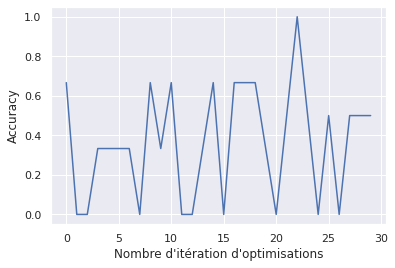

In [51]:


plt.plot(scores)
plt.xlabel("Nombre d'itération d'optimisations")
plt.ylabel("Accuracy")